<a href="https://colab.research.google.com/github/DarkLauroDFreitas/Calculo_N-merico_1_Miguel/blob/main/Eliminacao_Gauss_Animada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eliminação de Gauss — animação passo a passo

Cálculo Numérico · complemento visual do notebook `Sistemas_Lineares_Gauss_LU.ipynb`

Este notebook gera um **GIF** da eliminação de Gauss sobre a matriz aumentada $[A\mid b]$,
com a geometria ao lado: cada equação é um **plano** (sistemas $3\times3$) ou uma **reta**
(sistemas $2\times2$).

Durante cada operação de linha $R_i \leftarrow R_i - m_{ik}R_k$ o plano **gira** em torno da
reta onde corta o plano do pivô — e o ponto de interseção **não sai do lugar**. É a
demonstração visual de que a eliminação produz um sistema equivalente.

Só usa `numpy` e `Pillow`, que já vêm no Colab. Nada para instalar.

**Como usar:** menu *Ambiente de execução → Executar tudo*.

## Prévia do resultado

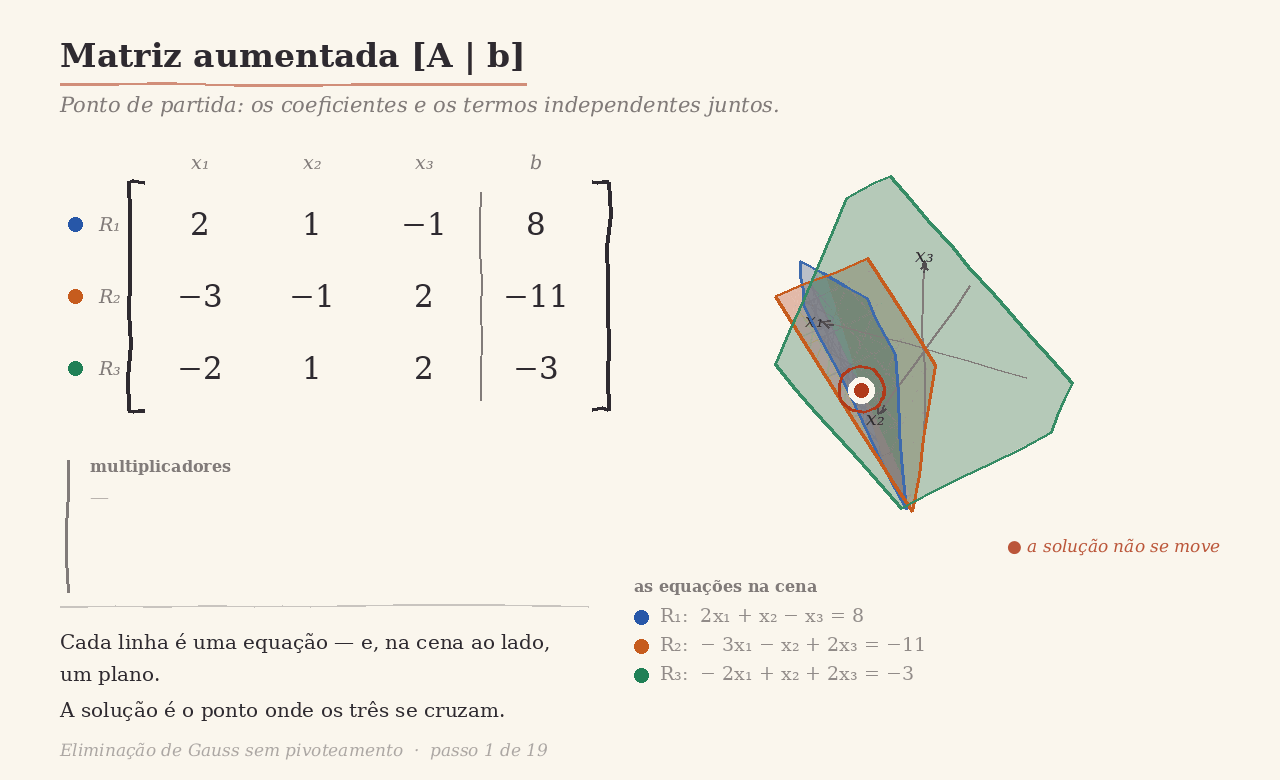

*O GIF acima é o que a seção 2 gera. Ele está embutido no notebook, então
aparece mesmo sem executar nada.*


## 1. O código

A célula abaixo grava o módulo `gauss_gif.py` no ambiente do Colab. É o programa inteiro:
a eliminação de Gauss, o desenho "à mão" da matriz e o traçado dos planos (um
*raycaster* em numpy — sem matplotlib).

In [ ]:
%%writefile gauss_gif.py
#!/usr/bin/env python3
"""GIF animado da eliminação de Gauss: a matriz e a geometria, lado a lado.

À esquerda, a matriz aumentada [A | b] passo a passo, na notação da aula: pivô,
multiplicador m_ik = a_ik / a_kk, a operação R_i <- R_i - m_ik R_k e a
substituição regressiva. À direita, a cena: cada equação é um plano (n = 3) ou
uma reta (n = 2). Durante cada operação de linha o plano gira continuamente em
torno da reta onde corta o plano do pivô — e o ponto solução fica parado o tempo
todo. É a demonstração visual de que a eliminação dá um sistema equivalente.

O desenho imita uma folha de caderno: papel creme, tipos serifados, traços com
tremor e marca-texto, em vez de tabela. Com --fonte é possível apontar para uma
fonte manuscrita (Caveat, Patrick Hand) e deixar tudo escrito à mão.

Depende apenas de numpy e Pillow (ambos já disponíveis no Colab).

Exemplos de uso:
    python3 gauss_gif.py
    python3 gauss_gif.py --pivoteamento
    python3 gauss_gif.py -A "4 -1 0; -1 4 -1; 0 -1 3" -b "100 100 50" -o termico.gif
    python3 gauss_gif.py -A "0 2; 1 1" -b "4 3" --pivoteamento   # retas, 2x2
    python3 gauss_gif.py --sem-geometria --tweens 0        # versão enxuta
    python3 gauss_gif.py --fonte ~/.fonts/Caveat-Regular.ttf
"""

from __future__ import annotations

import argparse
import math
from fractions import Fraction
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw, ImageFont

# --------------------------------------------------------------------------- #
# Aparência: papel, tinta e traço à mão
# --------------------------------------------------------------------------- #

MARGEM = 60

COR_PAPEL = (250, 246, 237)      # papel levemente creme
COR_CENA = COR_PAPEL             # a cena flutua na folha, sem moldura
TINTA = (46, 42, 48)             # grafite/nanquim
TINTA_CLARA = (128, 122, 120)
TINTA_NOVA = (28, 78, 166)       # caneta azul: valor que acabou de mudar
TINTA_ZERO = (22, 110, 72)       # caneta verde: o zero recém-criado
TINTA_RUBRICA = (176, 58, 26)    # caneta vermelha: ênfase e solução

MARCA_PIVO = (252, 206, 70)      # marca-texto amarelo
MARCA_FONTE = (128, 186, 240)    # marca-texto azul
MARCA_ALVO = (246, 168, 104)     # marca-texto laranja
MARCA_ZERO = (140, 214, 150)     # marca-texto verde
ALFA_MARCA = 0.46

CAMINHOS_FONTE = {
    "regular": [
        "/usr/share/fonts/TTF/DejaVuSerif.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf",
        "/usr/share/fonts/liberation/LiberationSerif-Regular.ttf",
    ],
    "bold": [
        "/usr/share/fonts/TTF/DejaVuSerif-Bold.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSerif-Bold.ttf",
        "/usr/share/fonts/liberation/LiberationSerif-Bold.ttf",
    ],
    "italico": [
        "/usr/share/fonts/TTF/DejaVuSerif-Italic.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSerif-Italic.ttf",
        "/usr/share/fonts/liberation/LiberationSerif-Italic.ttf",
    ],
}

# se o usuário passar --fonte, todas as famílias apontam para esse arquivo
FONTE_MANUSCRITA: str | None = None


def carregar_fonte(estilo: str, tamanho: int) -> ImageFont.FreeTypeFont:
    """Procura uma fonte TrueType no sistema; cai no pacote da Pillow se faltar."""
    if FONTE_MANUSCRITA:
        try:
            return ImageFont.truetype(FONTE_MANUSCRITA, tamanho)
        except OSError:
            pass
    for caminho in CAMINHOS_FONTE[estilo]:
        if Path(caminho).exists():
            return ImageFont.truetype(caminho, tamanho)
    nome = {"regular": "DejaVuSerif.ttf", "bold": "DejaVuSerif-Bold.ttf",
            "italico": "DejaVuSerif-Italic.ttf"}[estilo]
    try:
        return ImageFont.truetype(nome, tamanho)
    except OSError:
        return ImageFont.load_default(tamanho)


FONTES = {
    "titulo": ("bold", 33),
    "subtitulo": ("italico", 21),
    "celula": ("regular", 31),
    "celula_peq": ("regular", 25),
    "formula": ("italico", 22),
    "texto": ("regular", 20),
    "rotulo": ("italico", 19),
    "painel_titulo": ("bold", 16),
    "painel": ("regular", 19),
    "rodape": ("italico", 17),
}
_cache_fontes: dict[tuple, ImageFont.FreeTypeFont] = {}


def fonte(chave: str) -> ImageFont.FreeTypeFont:
    ident = (chave, FONTE_MANUSCRITA)
    if ident not in _cache_fontes:
        estilo, tamanho = FONTES[chave]
        _cache_fontes[ident] = carregar_fonte(estilo, tamanho)
    return _cache_fontes[ident]


# --------------------------------------------------------------------------- #
# Traço à mão
#
# O tremor é sorteado a partir da identidade do elemento (nunca do número do
# quadro), para que o desenho não fique vibrando de um quadro para o outro.
# --------------------------------------------------------------------------- #

def clarear(cor, t):
    """Puxa a cor para o branco: vira tom de marca-texto."""
    return tuple(int(round(c + (255 - c) * t)) for c in cor)


def mistura(cor, alfa, fundo=COR_PAPEL):
    """Cor opaca equivalente a `cor` com transparência `alfa` sobre o papel.

    Traço à mão é uma polilinha: com alfa real, cada emenda entre segmentos
    compõe duas vezes e a linha sai manchada. Pré-misturar resolve.
    """
    return tuple(int(round(c * alfa + f * (1 - alfa))) for c, f in zip(cor, fundo))


def _rng(chave) -> np.random.Generator:
    return np.random.default_rng(abs(hash(chave)) % (2**32))


def _pontos_mao(p0, p1, amp, rng, segmentos=None):
    p0, p1 = np.array(p0, dtype=float), np.array(p1, dtype=float)
    v = p1 - p0
    comp = float(np.linalg.norm(v))
    if comp < 1e-6:
        return [tuple(p0), tuple(p1)]
    u = v / comp
    perp = np.array([-u[1], u[0]])
    n = max(4, int(segmentos if segmentos else comp / 26))
    ts = np.linspace(0.0, 1.0, n)
    desvio = np.cumsum(rng.normal(0.0, 1.0, n))
    desvio -= np.linspace(desvio[0], desvio[-1], n)     # fixa as pontas
    pico = float(np.abs(desvio).max())
    if pico > 1e-9:
        desvio = desvio / pico * amp
    return [tuple(p0 + u * (comp * t) + perp * o) for t, o in zip(ts, desvio)]


def traco(d, p0, p1, cor, largura=3, amp=1.5, chave=None):
    """Uma linha reta, mas com a hesitação de quem desenhou à régua torta."""
    pts = _pontos_mao(p0, p1, amp, _rng(chave or (p0, p1, largura)))
    d.line(pts, fill=cor, width=largura, joint="curve")


def circulo_mao(d, caixa, cor, largura=3, amp=2.2, chave=None):
    """Circula algo como quem marca no papel — fecha passando um pouco do início."""
    x0, y0, x1, y1 = caixa
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    rx, ry = (x1 - x0) / 2, (y1 - y0) / 2
    rng = _rng(chave or ("circulo", x0, y0))
    n = 56
    ang = np.linspace(-0.35, 2 * np.pi + 0.5, n)
    ruido = np.cumsum(rng.normal(0.0, 1.0, n))
    ruido -= np.linspace(ruido[0], ruido[-1], n)
    pico = float(np.abs(ruido).max())
    if pico > 1e-9:
        ruido = ruido / pico * amp
    pts = [(cx + (rx + r) * np.cos(a), cy + (ry + r) * np.sin(a))
           for a, r in zip(ang, ruido)]
    d.line(pts, fill=cor, width=largura, joint="curve")


def colchete(d, x, y0, y1, lado, cor, largura=4, chave=None):
    """Colchete da matriz, desenhado em três traços como se faz no caderno."""
    dx = 16 if lado < 0 else -16
    traco(d, (x, y0), (x, y1), cor, largura, amp=2.0, chave=(chave, "vertical"))
    traco(d, (x, y0), (x + dx, y0), cor, largura, amp=1.2, chave=(chave, "topo"))
    traco(d, (x, y1), (x + dx, y1), cor, largura, amp=1.2, chave=(chave, "base"))


def marcador(d, caixa, cor, chave=None, tracos=4):
    """Passada de marca-texto: bordas irregulares, cantos redondos."""
    x0, y0, x1, y1 = caixa
    rng = _rng(chave or ("marca", x0, y0, cor))
    h = (y1 - y0) / tracos
    for t in range(tracos):
        yc = y0 + h * (t + 0.5) + rng.uniform(-1.2, 1.2)
        ja = x0 + rng.uniform(-4, 2)
        jb = x1 + rng.uniform(-2, 4)
        r = h * 0.60
        d.line([(ja, yc), (jb, yc)], fill=cor + (255,), width=int(h * 1.2) + 1)
        d.ellipse([ja - r, yc - r, ja + r, yc + r], fill=cor + (255,))
        d.ellipse([jb - r, yc - r, jb + r, yc + r], fill=cor + (255,))


# --------------------------------------------------------------------------- #
# Formatação de números
# --------------------------------------------------------------------------- #

SUBSCRITO = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")


def sub(n: int) -> str:
    """1 -> '₁', para escrever a₁₁, m₂₁, R₃ como no texto da aula."""
    return str(n).translate(SUBSCRITO)


USAR_FRACOES = True  # alternado pela opção --decimal


def _menos(t: str) -> str:
    """Sinal de menos tipográfico: fica melhor escrito do que o hífen."""
    return t.replace("-", "−")


def fmt(v: float, casas: int = 3) -> str:
    """Mostra frações exatas (1/2, -3/2) quando existem; senão, decimal."""
    if abs(v) < 1e-12:
        return "0"
    if not USAR_FRACOES:
        return _menos(f"{v:.{casas}f}".rstrip("0").rstrip("."))
    f = Fraction(v).limit_denominator(999)
    if abs(float(f) - v) < 1e-9:
        if f.denominator == 1:
            return _menos(str(f.numerator))
        return _menos(f"{f.numerator}/{f.denominator}")
    return _menos(f"{v:.{casas}f}".rstrip("0").rstrip("."))


# --------------------------------------------------------------------------- #
# Visão geométrica: cada equação é um plano (n=3) ou uma reta (n=2)
#
# A ideia que a animação quer mostrar: as operações de linha giram os planos,
# mas o ponto de interseção — a solução — fica parado. No fim, cada plano está
# alinhado a um eixo e a solução pode ser lida coordenada por coordenada.
# --------------------------------------------------------------------------- #

CORES_LINHA = [
    (40, 92, 170),    # R1 — azul
    (198, 92, 30),    # R2 — laranja
    (32, 128, 86),    # R3 — verde
    (122, 78, 168),   # R4 — roxo
]

LUZ = np.array([0.45, 0.35, 0.82])
LUZ = LUZ / np.linalg.norm(LUZ)


def cor_linha(i: int) -> tuple[int, int, int]:
    return CORES_LINHA[i % len(CORES_LINHA)]


ANGULO_CAMERA = (38.0, 26.0)


def direcao_visada(azimute, elevacao):
    az, el = np.radians(azimute), np.radians(elevacao)
    return -np.array([np.cos(el) * np.cos(az),
                      np.cos(el) * np.sin(az),
                      np.sin(el)])


def escolher_camera(matrizes):
    """Ângulo em que nenhum plano aparece de perfil.

    Um plano cuja normal é perpendicular à direção de visada degenera numa
    reta na tela. Varremos os ângulos e ficamos com o que maximiza o menor
    |n̂·d| ao longo de toda a animação — inclusive nos quadros do giro.
    """
    normais = []
    for M in matrizes:
        for i in range(M.shape[0]):
            n = M[i, :3].astype(float)
            norma = np.linalg.norm(n)
            if norma > 1e-12:
                normais.append(n / norma)
    if not normais:
        return ANGULO_CAMERA
    N = np.array(normais)

    azs = np.arange(0.0, 360.0, 6.0)
    els = np.arange(14.0, 47.0, 4.0)
    cand = [(a, e) for a in azs for e in els]
    D = np.array([direcao_visada(a, e) for a, e in cand])
    nota = np.abs(N @ D.T).min(axis=0)               # pior plano de cada ângulo

    # 0.20 ≈ 11° fora do perfil: já basta para o plano ter área na tela
    limiar = min(0.20, nota.max() * 0.9)
    bons = np.flatnonzero(nota >= limiar)
    # entre os bons, o mais perto do ângulo clássico de livro
    custo = [abs(cand[i][0] - 38.0) + 2 * abs(cand[i][1] - 26.0) for i in bons]
    return cand[int(bons[int(np.argmin(custo))])]


class Camera3D:
    """Câmera ortográfica: raios paralelos, bom para leitura de geometria."""

    def __init__(self, largura, altura, L, azimute=38.0, elevacao=26.0):
        self.W, self.H, self.L = largura, altura, L
        self.d = direcao_visada(azimute, elevacao)
        r = np.cross(self.d, np.array([0.0, 0.0, 1.0]))
        self.r = r / np.linalg.norm(r)
        u = np.cross(self.r, self.d)
        self.u = u / np.linalg.norm(u)
        # escala: projeta os 8 cantos da caixa e ajusta para caberem no painel
        cantos = np.array([[sx * L, sy * L, sz * L]
                           for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)])
        vao_x = float(np.ptp(cantos @ self.r))
        vao_y = float(np.ptp(cantos @ self.u))
        self.escala = max(vao_x / (largura * 0.90), vao_y / (altura * 0.90))
        self.cx, self.cy = largura / 2.0, altura / 2.0

    def projetar(self, p):
        p = np.asarray(p, dtype=float)
        return (self.cx + (p @ self.r) / self.escala,
                self.cy - (p @ self.u) / self.escala)


def poligono_plano(n, c, L):
    """Interseção do plano n·p = c com a caixa [-L,L]³, em ordem angular."""
    pts = []
    for eixo in range(3):
        if abs(n[eixo]) < 1e-12:
            continue
        a, b = [e for e in range(3) if e != eixo]
        for sa in (-L, L):
            for sb in (-L, L):
                p = np.zeros(3)
                p[a], p[b] = sa, sb
                t = (c - n @ p) / n[eixo]
                if -L - 1e-9 <= t <= L + 1e-9:
                    p[eixo] = t
                    pts.append(p)
    if len(pts) < 3:
        return []
    # remove duplicatas
    unicos = []
    for p in pts:
        if not any(np.allclose(p, q, atol=1e-7) for q in unicos):
            unicos.append(p)
    if len(unicos) < 3:
        return []
    P = np.array(unicos)
    centro = P.mean(axis=0)
    nn = n / np.linalg.norm(n)
    e1 = P[0] - centro
    e1 = e1 - (e1 @ nn) * nn
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(nn, e1)
    ang = np.arctan2((P - centro) @ e2, (P - centro) @ e1)
    return list(P[np.argsort(ang)])


def _rasterizar_planos(planos, cam, L, w, h, fundo, passo_grade=None):
    """Lança um raio por pixel; ordena por profundidade e compõe com alfa."""
    jj, ii = np.mgrid[0:h, 0:w]
    X = ((ii + 0.5) - w / 2.0) * cam.escala
    Y = (h / 2.0 - (jj + 0.5)) * cam.escala
    X = X.astype(np.float32)
    Y = Y.astype(np.float32)

    K = len(planos)
    T = np.full((K, h, w), -np.inf, dtype=np.float32)
    V = np.zeros((K, h, w), dtype=bool)
    G = np.ones((K, h, w), dtype=np.float32)
    cores = np.zeros((K, 3), dtype=np.float32)

    alfas = np.array([a for _, _, _, a in planos], dtype=np.float32)
    for k, (n, c, cor, _) in enumerate(planos):
        nd = float(n @ cam.d)
        if abs(nd) < 1e-7:          # plano visto de perfil: some
            continue
        # origem do raio: O = X·r + Y·u (câmera ortográfica centrada na origem)
        t = ((c - X * float(n @ cam.r) - Y * float(n @ cam.u)) / nd).astype(np.float32)
        dentro = np.ones((h, w), dtype=bool)
        comps = []
        for a in range(3):
            pa = X * float(cam.r[a]) + Y * float(cam.u[a]) + t * float(cam.d[a])
            dentro &= np.abs(pa) <= L
            comps.append(pa)
        T[k] = t
        V[k] = dentro
        # sombreamento constante (plano é chato) + grade leve para dar relevo
        sombra = 0.74 + 0.26 * abs(float(n @ LUZ) / np.linalg.norm(n))
        grade = np.ones((h, w), dtype=np.float32)
        if passo_grade:
            for pa in comps:
                f = np.abs(pa / passo_grade - np.round(pa / passo_grade))
                grade = np.where(f < 0.016, grade * 0.82, grade)
        G[k] = grade * sombra
        cores[k] = cor

    img = np.empty((h, w, 3), dtype=np.float32)
    img[:] = np.array(fundo, dtype=np.float32)

    Tm = np.where(V, T, -np.inf).astype(np.float32)
    ordem = np.argsort(-Tm, axis=0)              # do mais distante ao mais próximo
    for passo in range(K):
        sel = ordem[passo]
        val = np.take_along_axis(V, sel[None], 0)[0]
        if not val.any():
            continue
        g = np.take_along_axis(G, sel[None], 0)[0]
        cor = cores[sel]                          # (h, w, 3)
        a = (alfas[sel] * val).astype(np.float32)[..., None]
        img = img * (1 - a) + cor * g[..., None] * a
    return np.clip(img, 0, 255).astype(np.uint8)


def _seta(d, p0, p1, cor, largura=3, cabeca=11, chave=None):
    traco(d, p0, p1, cor, largura, amp=1.3, chave=(chave, "haste"))
    ang = np.arctan2(p1[1] - p0[1], p1[0] - p0[0])
    for lado in (+1, -1):
        a = ang + lado * np.radians(155)
        traco(d, p1, (p1[0] + cabeca * np.cos(a), p1[1] + cabeca * np.sin(a)),
              cor, largura, amp=0.8, chave=(chave, "ponta", lado))


def cena_3d(M, L, tam, papeis_linha, x_sol, x_conhecidos, mostrar_normais=True):
    """Desenha os planos das equações, os eixos e o ponto solução."""
    W, H = tam
    ss = 2
    cam = Camera3D(W * ss, H * ss, L, *ANGULO_CAMERA)

    planos = []
    for i in range(M.shape[0]):
        n = M[i, :3].astype(float)
        if np.linalg.norm(n) < 1e-12:
            continue
        # sem foco, todos iguais; com foco, os planos da operação vêm à frente
        if not papeis_linha:
            alfa = 0.30
        else:
            alfa = 0.42 if i in papeis_linha else 0.13
        planos.append((n, float(M[i, 3]), np.array(cor_linha(i), dtype=float), alfa))

    passo = L / 4.0
    bruto = _rasterizar_planos(planos, cam, L, W * ss, H * ss, COR_CENA, passo)
    img = Image.fromarray(bruto, "RGB").resize((W, H), Image.LANCZOS)

    cam_px = Camera3D(W, H, L, *ANGULO_CAMERA)
    d = ImageDraw.Draw(img, "RGBA")

    # eixos coordenados, a lápis
    for a, rot in enumerate(("x₁", "x₂", "x₃")):
        p0 = np.zeros(3); p0[a] = -L
        p1 = np.zeros(3); p1[a] = L
        traco(d, cam_px.projetar(p0), cam_px.projetar(p1),
              mistura(TINTA_CLARA, 0.95), largura=2, amp=1.4, chave=("eixo3", a))
        _seta(d, cam_px.projetar(p1 * 0.88), cam_px.projetar(p1),
              mistura(TINTA, 0.80), largura=2, cabeca=9, chave=("eixo3p", a))
        px, py = cam_px.projetar(p1 * 1.07)
        px = min(max(px, 14), W - 14)
        py = min(max(py, 14), H - 14)
        d.text((px, py), rot, font=fonte("rotulo"), fill=TINTA, anchor="mm")

    # contorno de cada plano (deixa a orientação legível mesmo com transparência)
    for i in range(M.shape[0]):
        n = M[i, :3].astype(float)
        if np.linalg.norm(n) < 1e-12:
            continue
        poli = poligono_plano(n, float(M[i, 3]), L)
        if len(poli) >= 3:
            proj = [cam_px.projetar(p) for p in poli]
            focado = bool(papeis_linha.get(i)) or not papeis_linha
            largura = 3 if focado else 2
            tom = mistura(cor_linha(i), 0.90 if focado else 0.45)
            for e in range(len(proj)):
                traco(d, proj[e], proj[(e + 1) % len(proj)], tom, largura,
                      amp=1.1, chave=("borda", i, e))

    # vetores normais das linhas em foco: é o que gira durante a operação
    if mostrar_normais:
        for i, papel in papeis_linha.items():
            if i >= M.shape[0]:
                continue
            n = M[i, :3].astype(float)
            nn = np.linalg.norm(n)
            if nn < 1e-12:
                continue
            base = np.asarray(x_sol, dtype=float) if x_sol is not None else np.zeros(3)
            ponta = base + (n / nn) * (L * 0.42)
            _seta(d, cam_px.projetar(base), cam_px.projetar(ponta),
                  cor_linha(i), largura=3, cabeca=10,
                  chave=("normal", i))

    # ponto solução: fixo do começo ao fim
    if x_sol is not None:
        sx, sy = cam_px.projetar(np.asarray(x_sol, dtype=float))
        # guias tracejadas para as coordenadas já determinadas
        for a in sorted(x_conhecidos):
            alvo = np.array(x_sol, dtype=float)
            alvo[a] = 0.0
            ax, ay = cam_px.projetar(alvo)
            _tracejado(d, (sx, sy), (ax, ay), mistura(TINTA_RUBRICA, 0.85))
            d.ellipse([ax - 4, ay - 4, ax + 4, ay + 4],
                      fill=mistura(TINTA_RUBRICA, 0.85))
        d.ellipse([sx - 13, sy - 13, sx + 13, sy + 13], fill=COR_PAPEL)
        d.ellipse([sx - 7, sy - 7, sx + 7, sy + 7], fill=TINTA_RUBRICA)
        circulo_mao(d, (sx - 22, sy - 22, sx + 22, sy + 22),
                    TINTA_RUBRICA, largura=3, amp=2.4,
                    chave=("sol3", 0))
    return img


def _tracejado(d, p0, p1, cor, traco=8, vao=5, largura=3):
    p0, p1 = np.array(p0, dtype=float), np.array(p1, dtype=float)
    comp = np.linalg.norm(p1 - p0)
    if comp < 1e-6:
        return
    u = (p1 - p0) / comp
    t = 0.0
    while t < comp:
        a = p0 + u * t
        b = p0 + u * min(t + traco, comp)
        d.line([tuple(a), tuple(b)], fill=cor, width=largura)
        t += traco + vao


def _clip_reta_caixa(n, c, L):
    """Interseção da reta n·p = c com o quadrado [-L,L]²."""
    pts = []
    for eixo in range(2):
        if abs(n[eixo]) < 1e-12:
            continue
        outro = 1 - eixo
        for s in (-L, L):
            p = np.zeros(2)
            p[outro] = s
            t = (c - n @ p) / n[eixo]
            if -L - 1e-9 <= t <= L + 1e-9:
                p[eixo] = t
                pts.append(p.copy())
    unicos = []
    for p in pts:
        if not any(np.allclose(p, q, atol=1e-7) for q in unicos):
            unicos.append(p)
    return unicos[:2]


def cena_2d(M, L, tam, papeis_linha, x_sol, x_conhecidos, mostrar_normais=True):
    """Duas equações, duas retas: a interseção é a solução."""
    W, H = tam
    img = Image.new("RGB", (W, H), COR_CENA)
    d = ImageDraw.Draw(img, "RGBA")
    esc = (2.0 * L * 1.15) / min(W, H)
    cx, cy = W / 2.0, H / 2.0

    def proj(p):
        return (cx + p[0] / esc, cy - p[1] / esc)

    # papel quadriculado, a lápis
    passo = L / 4.0
    for k in range(-4, 5):
        v = k * passo
        traco(d, proj((v, -L)), proj((v, L)), mistura(TINTA_CLARA, 0.24), 1, amp=1.0,
              chave=("gradev", k))
        traco(d, proj((-L, v)), proj((L, v)), mistura(TINTA_CLARA, 0.24), 1, amp=1.0,
              chave=("gradeh", k))
    for a, rot in enumerate(("x₁", "x₂")):
        p1 = np.zeros(2); p1[a] = L
        p0 = np.zeros(2); p0[a] = -L
        traco(d, proj(p0), proj(p1), mistura(TINTA_CLARA, 0.72), 2, amp=1.2,
              chave=("eixo2", a))
        _seta(d, proj(p1 * 0.92), proj(p1), mistura(TINTA, 0.82), largura=2, cabeca=9,
              chave=("eixo2p", a))
        px, py = proj(p1 * 1.05)
        px = min(max(px, 14), W - 14)
        py = min(max(py, 14), H - 14)
        d.text((px, py), rot, font=fonte("rotulo"), fill=TINTA, anchor="mm")

    for i in range(M.shape[0]):
        n = M[i, :2].astype(float)
        if np.linalg.norm(n) < 1e-12:
            continue
        pts = _clip_reta_caixa(n, float(M[i, 2]), L)
        if len(pts) == 2:
            focado = bool(papeis_linha.get(i)) or not papeis_linha
            traco(d, proj(pts[0]), proj(pts[1]),
                  mistura(cor_linha(i), 1.0 if focado else 0.5),
                  5 if focado else 3, amp=1.4, chave=("reta", i))

    if mostrar_normais:
        for i, papel in papeis_linha.items():
            if i >= M.shape[0]:
                continue
            n = M[i, :2].astype(float)
            nn = np.linalg.norm(n)
            if nn < 1e-12:
                continue
            base = np.asarray(x_sol, dtype=float) if x_sol is not None else np.zeros(2)
            ponta = base + (n / nn) * (L * 0.38)
            _seta(d, proj(base), proj(ponta), cor_linha(i),
                  largura=3, cabeca=10, chave=("normal2", i))

    if x_sol is not None:
        sx, sy = proj(np.asarray(x_sol, dtype=float))
        for a in sorted(x_conhecidos):
            alvo = np.array(x_sol, dtype=float)
            alvo[a] = 0.0
            _tracejado(d, (sx, sy), proj(alvo), mistura(TINTA_RUBRICA, 0.85))
        d.ellipse([sx - 10, sy - 10, sx + 10, sy + 10], fill=COR_PAPEL)
        d.ellipse([sx - 6, sy - 6, sx + 6, sy + 6], fill=TINTA_RUBRICA)
        circulo_mao(d, (sx - 19, sy - 19, sx + 19, sy + 19),
                    TINTA_RUBRICA, largura=2, amp=2.4, chave=("sol2", 0))
    return img


def equacao_linha(M, i, n):
    """Texto '2x₁ + x₂ − x₃ = 8' para a legenda da cena."""
    partes = []
    for j in range(n):
        v = M[i, j]
        if abs(v) < 1e-12:
            continue
        s = "−" if v < 0 else ("+" if partes else "")
        mag = fmt(abs(v))
        coef = "" if mag == "1" else (f"({mag})" if "/" in mag else mag)
        partes.append(f"{s} {coef}x{sub(j+1)}".strip())
    esq = " ".join(partes) if partes else "0"
    return f"{esq} = {fmt(M[i, n])}"


# --------------------------------------------------------------------------- #
# Geração dos quadros (a matemática)
# --------------------------------------------------------------------------- #

class Quadro:
    """Um estado da animação: a matriz mais o que destacar e o que explicar."""

    def __init__(self, M, titulo, subtitulo="", linhas=(), pivo=None,
                 papeis_linha=None, celulas=None, prontas=0, duracao=1600,
                 multiplicadores=(), x=None, x_conhecidos=(), tween=False):
        self.M = np.array(M, dtype=float, copy=True)
        self.titulo = titulo
        self.subtitulo = subtitulo
        self.linhas = list(linhas)              # texto explicativo do rodapé
        self.pivo = pivo                        # (i, j) da célula do pivô
        self.papeis_linha = dict(papeis_linha or {})   # i -> 'fonte' | 'alvo'
        self.celulas = dict(celulas or {})      # (i, j) -> 'novo' | 'zero'
        self.prontas = prontas                  # nº de colunas já eliminadas
        self.duracao = duracao                  # milissegundos
        self.multiplicadores = list(multiplicadores)
        self.x = None if x is None else np.array(x, dtype=float, copy=True)
        self.x_conhecidos = set(x_conhecidos)
        self.tween = tween                      # quadro intermediário do giro


def gerar_quadros(A, b, pivoteamento=False, tol=1e-12, tweens=10, x_ref=None):
    """Executa a eliminação de Gauss guardando um quadro por etapa.

    Entre dois estados de uma operação de linha são inseridos `tweens` quadros
    intermediários: na cena geométrica, o plano da linha alvo gira em torno da
    reta em que ela corta o plano do pivô — e o ponto solução não sai do lugar.
    """
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(b)
    if A.shape != (n, n):
        raise ValueError("A precisa ser quadrada e compatível com b")

    M = np.column_stack([A, b])
    quadros: list[Quadro] = []
    mults: list[str] = []

    tem_cena = x_ref is not None
    figura = "plano" if n == 3 else "reta"
    artigo = "O" if n == 3 else "A"
    paralelo = "paralelo" if n == 3 else "paralela"

    quadros.append(Quadro(
        M, "Matriz aumentada [A | b]",
        "Ponto de partida: os coeficientes e os termos independentes juntos.",
        ([f"Cada linha é uma equação — e, na cena ao lado, {'um plano' if n == 3 else 'uma reta'}.",
          f"A solução é o ponto onde {'os três se cruzam' if n == 3 else 'as duas se cruzam'}."]
         if tem_cena else
         ["Objetivo: zerar tudo abaixo da diagonal usando operações de linha,",
          "chegando a um sistema triangular superior equivalente."]),
        duracao=2800, x=x_ref, x_conhecidos=(),
    ))

    for k in range(n - 1):
        if pivoteamento:
            p = k + int(np.argmax(np.abs(M[k:, k])))
            if abs(M[p, k]) < tol:
                raise np.linalg.LinAlgError("Matriz singular ou pivô muito pequeno")
            if p != k:
                quadros.append(Quadro(
                    M, f"Coluna {k+1} — pivoteamento parcial",
                    f"O maior elemento em módulo da coluna está na linha {p+1}.",
                    [f"|{fmt(M[p, k])}| > |{fmt(M[k, k])}|  →  trocar R{sub(k+1)} ↔ R{sub(p+1)}",
                     "Trocar equações de lugar não muda a geometria, só a ordem."],
                    pivo=(p, k), papeis_linha={k: "alvo", p: "fonte"},
                    prontas=k, multiplicadores=mults, duracao=2400, x=x_ref,
                ))
                M[[k, p], :] = M[[p, k], :]
                quadros.append(Quadro(
                    M, f"Coluna {k+1} — linhas trocadas",
                    f"R{sub(k+1)} ↔ R{sub(p+1)} feita; o novo pivô já está na posição.",
                    [f"Pivô da etapa: a{sub(k+1)}{sub(k+1)} = {fmt(M[k, k])}"],
                    pivo=(k, k), papeis_linha={k: "fonte", p: "alvo"},
                    prontas=k, multiplicadores=mults, duracao=2000, x=x_ref,
                ))

        if abs(M[k, k]) < tol:
            raise np.linalg.LinAlgError(
                f"Pivô nulo na coluna {k+1}: é necessária uma troca de linhas "
                "(rode com --pivoteamento)")

        quadros.append(Quadro(
            M, f"Coluna {k+1} — escolher o pivô",
            f"O pivô é a{sub(k+1)}{sub(k+1)} = {fmt(M[k, k])}.",
            [f"Vamos zerar o elemento abaixo dele usando R{sub(k+1)}."
             if n - k - 1 == 1 else
             f"Vamos zerar os {n - k - 1} elementos abaixo dele usando R{sub(k+1)}."],
            pivo=(k, k), papeis_linha={k: "fonte"},
            prontas=k, multiplicadores=mults, duracao=2200, x=x_ref,
        ))

        for i in range(k + 1, n):
            m = M[i, k] / M[k, k]
            rot = f"m{sub(i+1)}{sub(k+1)}"
            sinal = "+" if m < 0 else "−"
            quadros.append(Quadro(
                M, f"Eliminar a{sub(i+1)}{sub(k+1)}",
                f"Multiplicador: {rot} = a{sub(i+1)}{sub(k+1)} / a{sub(k+1)}{sub(k+1)}"
                f" = {fmt(M[i, k])} / {fmt(M[k, k])} = {fmt(m)}",
                [f"R{sub(i+1)} ← R{sub(i+1)} − {rot}·R{sub(k+1)}"
                 f"  =  R{sub(i+1)} {sinal} {fmt(abs(m))}·R{sub(k+1)}",
                 *([f"Acompanhe {'o plano' if n == 3 else 'a reta'} de R{sub(i+1)} girar "
                    f"em torno {'da reta onde ele corta o plano' if n == 3 else 'do ponto onde ela corta a reta'}"
                    " do pivô."] if tem_cena else [])],
                pivo=(k, k), papeis_linha={k: "fonte", i: "alvo"},
                prontas=k, multiplicadores=mults, duracao=2600, x=x_ref,
            ))

            # --- o giro, quadro a quadro --- #
            origem = M[i].copy()
            for passo in range(1, (tweens if abs(m) > tol else 0) + 1):
                s = passo / (tweens + 1.0)
                s = 0.5 - 0.5 * np.cos(np.pi * s)        # suaviza início e fim
                Mt = M.copy()
                Mt[i] = origem - s * m * M[k]
                quadros.append(Quadro(
                    Mt, f"Eliminar a{sub(i+1)}{sub(k+1)}",
                    f"R{sub(i+1)} ← R{sub(i+1)} {sinal} {fmt(abs(m))}·R{sub(k+1)}"
                    f"   ({100*s:.0f}% da operação)",
                    [f"{artigo} {figura} gira, mas a solução continua no mesmo ponto."],
                    pivo=(k, k), papeis_linha={k: "fonte", i: "alvo"},
                    celulas={(i, j): "novo" for j in range(k, n + 1)},
                    prontas=k, multiplicadores=mults, duracao=70,
                    x=x_ref, tween=True,
                ))

            M[i, k:] -= m * M[k, k:]
            M[i, k] = 0.0
            mults = mults + [f"{rot} = {fmt(m)}"]
            celulas = {(i, j): "novo" for j in range(k + 1, n + 1)}
            celulas[(i, k)] = "zero"
            quadros.append(Quadro(
                M, f"Eliminar a{sub(i+1)}{sub(k+1)}",
                f"Zero criado na posição ({i+1}, {k+1}); a incógnita "
                f"x{sub(k+1)} saiu da equação {i+1}.",
                [f"R{sub(i+1)} = [ " + "   ".join(fmt(v) for v in M[i, :n])
                 + "  |  " + fmt(M[i, n]) + " ]",
                 *([f"{artigo} {figura} de R{sub(i+1)} ficou {paralelo} ao eixo "
                    f"x{sub(k+1)}."] if tem_cena else [])],
                pivo=(k, k), papeis_linha={k: "fonte", i: "alvo"},
                celulas=celulas, prontas=k, multiplicadores=mults, duracao=2600,
                x=x_ref,
            ))

        quadros.append(Quadro(
            M, f"Coluna {k+1} concluída",
            "Abaixo do pivô só restam zeros.",
            ["Seguimos para a próxima coluna, repetindo o mesmo procedimento."]
            if k + 1 < n - 1 else ["A matriz já está triangular superior."],
            prontas=k + 1, multiplicadores=mults, duracao=1900, x=x_ref,
        ))

    if abs(M[n - 1, n - 1]) < tol:
        raise np.linalg.LinAlgError("Último pivô nulo: o sistema não tem solução única")

    quadros.append(Quadro(
        M, "Forma triangular superior [U | c]",
        "Fim da eliminação: o sistema equivalente já pode ser resolvido.",
        ([f"{'Os planos giraram' if n == 3 else 'As retas giraram'} até se alinharem "
          "aos eixos — e o ponto não se moveu.",
          "Agora resolvemos de baixo para cima: substituição regressiva."]
         if tem_cena else
         ["Agora resolvemos de baixo para cima: substituição regressiva."]),
        prontas=n - 1, multiplicadores=mults, duracao=3000, x=x_ref,
    ))

    # ----- substituição regressiva ----- #
    x = np.zeros(n)
    conhecidos: set[int] = set()
    for i in range(n - 1, -1, -1):
        termos = " ".join(
            f"− {fmt(M[i, j])}·x{sub(j+1)}" for j in range(i + 1, n))
        quadros.append(Quadro(
            M, f"Substituição regressiva — x{sub(i+1)}",
            f"Usamos a linha {i+1}, onde só x{sub(i+1)} ainda é desconhecido.",
            [f"x{sub(i+1)} = ( {fmt(M[i, n])} {termos} ) / {fmt(M[i, i])}"
             if termos else f"x{sub(i+1)} = {fmt(M[i, n])} / {fmt(M[i, i])}"],
            papeis_linha={i: "alvo"}, prontas=n - 1,
            x=x_ref, x_conhecidos=conhecidos, duracao=2400,
        ))
        x[i] = (M[i, n] - M[i, i + 1:n] @ x[i + 1:]) / M[i, i]
        conhecidos = conhecidos | {i}
        quadros.append(Quadro(
            M, f"Substituição regressiva — x{sub(i+1)}",
            f"x{sub(i+1)} = {fmt(x[i])}",
            ([f"A guia tracejada marca a coordenada x{sub(i+1)} do ponto."]
             if tem_cena else
             ["Esse valor entra nas equações de cima na próxima etapa."])
            if i > 0 else ["Todas as incógnitas foram determinadas."],
            papeis_linha={i: "alvo"}, prontas=n - 1,
            x=x_ref, x_conhecidos=conhecidos, duracao=2400,
        ))

    r = b - A @ x
    resumo = ",   ".join(f"x{sub(j+1)} = {fmt(x[j])}" for j in range(n))
    if USAR_FRACOES and any("/" in fmt(v) for v in x):
        resumo += "   ≈   " + ",   ".join(
            f"{_menos(f'{x[j]:.4f}')}" for j in range(n))
    quadros.append(Quadro(
        M, "Solução", resumo,
        ["Conferência pelo resíduo r = b − Ax:",
         "‖r‖ = " + f"{np.linalg.norm(r):.2e}" + "   (zero, a menos do arredondamento)"],
        prontas=n - 1, x=x_ref, x_conhecidos=set(range(n)), duracao=4500,
    ))
    return quadros, x


# --------------------------------------------------------------------------- #
# Desenho de um quadro
# --------------------------------------------------------------------------- #

def _texto(d, xy, txt, chave, cor, ancora="la"):
    d.text(xy, txt, font=fonte(chave), fill=cor, anchor=ancora)


def quebrar(txt, chave, largura_max):
    """Quebra o texto em linhas que caibam na largura disponível."""
    f = fonte(chave)
    linhas, atual = [], ""
    for palavra in txt.split():
        teste = f"{atual} {palavra}".strip()
        if atual and f.getlength(teste) > largura_max:
            linhas.append(atual)
            atual = palavra
        else:
            atual = teste
    if atual:
        linhas.append(atual)
    return linhas


def _marcas_matriz(marca, q, gx, gy, cw, ch, ncol, geo=False):
    """Passadas de marca-texto atrás dos números (camada separada, opaca).

    Com a cena ao lado, a faixa usa a cor do próprio plano da linha: assim a
    ligação entre a linha da matriz e o plano é imediata. Sem cena, volta ao
    par azul (linha do pivô) / laranja (linha que muda).
    """
    largura_total = ncol * cw
    for i, papel in q.papeis_linha.items():
        if geo:
            cor = clarear(cor_linha(i), 0.62 if papel == "fonte" else 0.40)
        else:
            cor = MARCA_FONTE if papel == "fonte" else MARCA_ALVO
        y = gy + i * ch
        marcador(marca, (gx + 4, y + ch * 0.13, gx + largura_total - 4,
                         y + ch * 0.87), cor, chave=("linha", i, papel))
    for (i, j), tipo in q.celulas.items():
        if tipo != "zero":
            continue
        x, y = gx + j * cw, gy + i * ch
        marcador(marca, (x + cw * 0.22, y + ch * 0.16, x + cw * 0.78,
                         y + ch * 0.84), MARCA_ZERO, chave=("zero", i, j))
    if q.pivo is not None:
        i, j = q.pivo
        x, y = gx + j * cw, gy + i * ch
        marcador(marca, (x + cw * 0.17, y + ch * 0.12, x + cw * 0.83,
                         y + ch * 0.88), MARCA_PIVO, chave=("pivo", i, j))


def _desenhar_matriz(d, q, gx, gy, cw, ch, geo):
    """Números soltos entre colchetes, como escritos no caderno."""
    n, ncol = q.M.shape
    fmt_cel = ((lambda v: _menos("0.00" if abs(v) < 5e-3 else f"{v:.2f}"))
               if q.tween else fmt)
    # número comprido (83.333) encostaria na barra: cai para o corpo menor
    textos = [fmt_cel(v) for v in q.M.ravel()]
    chave_num = "celula"
    if max(fonte("celula").getlength(t) for t in textos) > cw * 0.80:
        chave_num = "celula_peq"

    for i in range(n):
        for j in range(ncol):
            xm = gx + j * cw + cw / 2
            ym = gy + i * ch + ch / 2
            marca = q.celulas.get((i, j))
            cor = TINTA
            if marca == "novo":
                cor = TINTA_NOVA
            elif marca == "zero":
                cor = TINTA_ZERO
            elif j < q.prontas and i > j:
                cor = TINTA_CLARA          # zona já eliminada, apagada
            _texto(d, (xm, ym), fmt_cel(q.M[i, j]), chave_num, cor, ancora="mm")

    altura = n * ch
    largura = ncol * cw
    # barra da matriz aumentada
    xb = gx + (ncol - 1) * cw
    traco(d, (xb, gy + 4), (xb, gy + altura - 4), TINTA_CLARA, 2, amp=1.8,
          chave=("barra", ncol))
    colchete(d, gx - 16, gy - 6, gy + altura + 6, -1, TINTA, 4, chave="colch_esq")
    colchete(d, gx + largura + 16, gy - 6, gy + altura + 6, +1, TINTA, 4,
             chave="colch_dir")

    # o pivô ganha um círculo de caneta
    if q.pivo is not None:
        i, j = q.pivo
        x, y = gx + j * cw, gy + i * ch
        circulo_mao(d, (x + cw * 0.20, y + ch * 0.12, x + cw * 0.80,
                        y + ch * 0.88), TINTA_RUBRICA, largura=3,
                    chave=("circ_pivo", i, j))

    for i in range(n):
        ym = gy + i * ch + ch / 2
        if geo:
            d.ellipse([gx - 76, ym - 7, gx - 62, ym + 7], fill=cor_linha(i))
        _texto(d, (gx - 34, ym), f"R{sub(i+1)}", "rotulo", TINTA_CLARA, ancora="mm")
    for j in range(ncol):
        rot = f"x{sub(j+1)}" if j < ncol - 1 else "b"
        _texto(d, (gx + j * cw + cw / 2, gy - 26), rot, "rotulo",
               TINTA_CLARA, ancora="mm")
    return gy + altura


def _desenhar_painel(d, q, px, py, pw, ph):
    """Nota de margem: sem caixa cinza, só um filete e o texto."""
    traco(d, (px, py + 4), (px, py + ph - 4), TINTA_CLARA, 3, amp=1.6,
          chave=("filete", px))
    if q.x is not None and q.x_conhecidos:
        _texto(d, (px + 22, py), "solução lida até aqui", "painel_titulo",
               TINTA_CLARA)
        for j in range(len(q.x)):
            conhecido = j in q.x_conhecidos
            texto = f"x{sub(j+1)} = {fmt(q.x[j])}" if conhecido else f"x{sub(j+1)} = ?"
            cor = TINTA_RUBRICA if conhecido else (188, 182, 178)
            _texto(d, (px + 22, py + 30 + j * 30), texto, "painel", cor)
    else:
        _texto(d, (px + 22, py), "multiplicadores", "painel_titulo", TINTA_CLARA)
        if q.multiplicadores:
            for idx, m in enumerate(q.multiplicadores[-4:]):
                _texto(d, (px + 22, py + 30 + idx * 28), m, "painel", TINTA)
        else:
            _texto(d, (px + 22, py + 30), "—", "painel", (188, 182, 178))


def desenhar(q: Quadro, legenda: str, L=None, geo=False) -> Image.Image:
    n, ncol = q.M.shape
    W, H = (1280, 780) if geo else (1120, 600)
    img = Image.new("RGB", (W, H), COR_PAPEL)

    if geo:
        cw, ch, gx, gy = 112, 72, MARGEM + 84, 188
    else:
        cw, ch, gx, gy = 118, 76, MARGEM + 84, 176

    # 1) marca-texto por baixo de tudo, numa camada própria (evita borrão)
    camada = Image.new("RGBA", (W, H), (0, 0, 0, 0))
    _marcas_matriz(ImageDraw.Draw(camada), q, gx, gy, cw, ch, ncol, geo)
    alfa = camada.getchannel("A").point(lambda a: int(a * ALFA_MARCA))
    camada.putalpha(alfa)
    img = Image.alpha_composite(img.convert("RGBA"), camada).convert("RGB")

    d = ImageDraw.Draw(img, "RGBA")

    # 2) cabeçalho
    _texto(d, (MARGEM, 36), q.titulo, "titulo", TINTA)
    caixa = d.textbbox((MARGEM, 36), q.titulo, font=fonte("titulo"))
    traco(d, (MARGEM, caixa[3] + 9), (caixa[2], caixa[3] + 9), mistura(TINTA_RUBRICA, 0.55),
          3, amp=1.6, chave=("sublinha_titulo", q.titulo))
    if q.subtitulo:
        sy = 92
        for parte in quebrar(q.subtitulo, "subtitulo", W - 2 * MARGEM)[:2]:
            _texto(d, (MARGEM, sy), parte, "subtitulo", TINTA_CLARA)
            sy += 28

    # 3) matriz
    fim = _desenhar_matriz(d, q, gx, gy, cw, ch, geo)

    if geo:
        _desenhar_painel(d, q, MARGEM + 8, fim + 52, 520, 140)
        ty = fim + 226
    else:
        _desenhar_painel(d, q, gx + ncol * cw + 74, gy + 6,
                         W - MARGEM - (gx + ncol * cw + 74), max(n * ch, 150))
        ty = fim + 62

    # 4) explicação (sem invadir a coluna da cena)
    limite = (628 - 40) if geo else (W - MARGEM)
    traco(d, (MARGEM, ty - 24), (limite, ty - 24), mistura(TINTA_CLARA, 0.38), 2,
          amp=1.6, chave=("regua", ty))
    for linha in q.linhas:
        chave = "formula" if any(s in linha for s in ("←", "=", "‖")) else "texto"
        for parte in quebrar(linha, chave, limite - MARGEM):
            _texto(d, (MARGEM, ty), parte, chave, TINTA)
            ty += 32
        ty += 4

    # 5) cena geométrica
    if geo:
        gx0, gy0 = 628, 150
        cw_cena, ch_cena = W - MARGEM - gx0, 400
        args = (q.M, L, (cw_cena, ch_cena), q.papeis_linha, q.x, q.x_conhecidos)
        img.paste(cena_3d(*args) if n == 3 else cena_2d(*args), (gx0, gy0))
        d = ImageDraw.Draw(img, "RGBA")

        ly = gy0 + ch_cena + 26
        _texto(d, (gx0 + 6, ly), "as equações na cena", "painel_titulo", TINTA_CLARA)
        ly += 28
        for i in range(n):
            d.ellipse([gx0 + 6, ly + 6, gx0 + 20, ly + 20], fill=cor_linha(i))
            realce = TINTA if q.papeis_linha.get(i) else (150, 144, 140)
            _texto(d, (gx0 + 32, ly), f"R{sub(i+1)}:  " + equacao_linha(q.M, i, n),
                   "painel", realce)
            ly += 29
        _texto(d, (W - MARGEM, gy0 + ch_cena + 2), "● a solução não se move",
               "rodape", mistura(TINTA_RUBRICA, 0.85), ancora="rs")

    _texto(d, (MARGEM, H - 40), legenda, "rodape", (176, 170, 166))
    return img


# --------------------------------------------------------------------------- #
# CLI
# --------------------------------------------------------------------------- #

def ler_matriz(s: str) -> np.ndarray:
    return np.array([[float(v) for v in linha.replace(",", " ").split()]
                     for linha in s.strip().split(";")], dtype=float)


def ler_vetor(s: str) -> np.ndarray:
    return np.array([float(v) for v in s.replace(",", " ").replace(";", " ").split()],
                    dtype=float)


def escala_cena(x_ref, A, b):
    """Meio-lado da caixa da cena: o ponto solução precisa caber com folga."""
    vals = [3.0]
    if x_ref is not None:
        vals.append(1.75 * float(np.max(np.abs(x_ref))))
    vals.append(0.9 * float(np.max(np.abs(b))) / max(float(np.max(np.abs(A))), 1e-9))
    L = max(vals)
    # arredonda para um valor "redondo", que deixa a grade legível
    mag = 10 ** math.floor(math.log10(L))
    return math.ceil(L / (mag / 2)) * (mag / 2)


def gerar_gif(A, b, saida="eliminacao_gauss.gif", pivoteamento=False,
              velocidade=1.0, decimal=False, pasta_png=None,
              geometria=True, tweens=10):
    """Gera o GIF e devolve (caminho, solução). Uso direto no Colab:

        from gauss_gif import gerar_gif
        caminho, x = gerar_gif([[2,1,-1],[-3,-1,2],[-2,1,2]], [8,-11,-3])
        from IPython.display import Image; Image(str(caminho))
    """
    global USAR_FRACOES
    USAR_FRACOES = not decimal

    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    n = len(b)

    geo = bool(geometria) and n in (2, 3)
    x_ref, L = None, None
    if geo:
        try:
            x_ref = np.linalg.solve(A, b)
            L = escala_cena(x_ref, A, b)
        except np.linalg.LinAlgError:
            geo, x_ref = False, None

    quadros, x = gerar_quadros(A, b, pivoteamento=pivoteamento,
                               tweens=tweens if geo else 0, x_ref=x_ref)

    if geo and n == 3:
        global ANGULO_CAMERA
        ANGULO_CAMERA = escolher_camera([q.M for q in quadros])

    modo = "com pivoteamento parcial" if pivoteamento else "sem pivoteamento"
    principais = [q for q in quadros if not q.tween]
    imagens, duracoes, passo = [], [], 0
    for q in quadros:
        if not q.tween:
            passo += 1
        legenda = (f"Eliminação de Gauss {modo}  ·  passo {passo} de "
                   f"{len(principais)}")
        imagens.append(desenhar(q, legenda, L=L, geo=geo))
        duracoes.append(max(40, int(q.duracao / max(velocidade, 0.05))))

    if pasta_png:
        pasta = Path(pasta_png)
        pasta.mkdir(parents=True, exist_ok=True)
        for idx, img in enumerate(imagens, start=1):
            img.save(pasta / f"quadro_{idx:03d}.png")

    saida = Path(saida)
    # paleta global adaptativa: mantém o arquivo pequeno com muitos quadros
    amostra = imagens[len(imagens) // 2]
    paleta = amostra.quantize(colors=128, method=Image.MAXCOVERAGE)
    quantizadas = [im.quantize(palette=paleta, dither=Image.NONE)
                   for im in imagens]
    quantizadas[0].save(saida, save_all=True, append_images=quantizadas[1:],
                        duration=duracoes, loop=0, optimize=True)
    return saida, x


def main() -> None:
    p = argparse.ArgumentParser(
        description="Gera um GIF da eliminação de Gauss em [A | b], com a "
                    "geometria (planos/retas) ao lado.")
    p.add_argument("-A", "--matriz", default="2 1 -1; -3 -1 2; -2 1 2",
                   help='linhas separadas por ";" (padrão: exemplo da aula)')
    p.add_argument("-b", "--vetor", default="8 -11 -3",
                   help="termos independentes")
    p.add_argument("-o", "--saida", default="eliminacao_gauss.gif",
                   help="arquivo GIF de saída")
    p.add_argument("--pivoteamento", action="store_true",
                   help="usa pivoteamento parcial (troca de linhas)")
    p.add_argument("--decimal", action="store_true",
                   help="mostra decimais em vez de frações exatas")
    p.add_argument("--sem-geometria", dest="geometria", action="store_false",
                   help="só a matriz, sem a cena dos planos")
    p.add_argument("--tweens", type=int, default=10,
                   help="quadros intermediários por operação de linha (0 desliga)")
    p.add_argument("--velocidade", type=float, default=1.0,
                   help="multiplica a duração dos quadros (1.5 = mais rápido)")
    p.add_argument("--fonte", metavar="TTF",
                   help="arquivo .ttf a usar (ex.: uma fonte manuscrita)")
    p.add_argument("--png", metavar="DIR",
                   help="também salva cada quadro como PNG na pasta indicada")
    args = p.parse_args()

    if args.fonte:
        global FONTE_MANUSCRITA
        FONTE_MANUSCRITA = args.fonte

    A, b = ler_matriz(args.matriz), ler_vetor(args.vetor)
    saida, x = gerar_gif(A, b, saida=args.saida, pivoteamento=args.pivoteamento,
                         velocidade=args.velocidade, decimal=args.decimal,
                         pasta_png=args.png, geometria=args.geometria,
                         tweens=max(0, args.tweens))

    print(f"GIF salvo em: {saida.resolve()}")
    print(f"{saida.stat().st_size/1024:.0f} KB")
    print("Solução:", ",  ".join(f"x{sub(j+1)} = {fmt(x[j])}" for j in range(len(x))))
    print("Resíduo ‖b − Ax‖ =", f"{np.linalg.norm(b - A @ x):.2e}")


if __name__ == "__main__":
    main()


## 2. Gerar o GIF do exemplo da aula

O sistema trabalhado à mão na seção 3 do notebook da disciplina:

$$\begin{aligned}2x+y-z&=8\\-3x-y+2z&=-11\\-2x+y+2z&=-3\end{aligned}$$

In [ ]:
from gauss_gif import gerar_gif
from IPython.display import Image, display

caminho, x = gerar_gif(
    A=[[2, 1, -1],
       [-3, -1, 2],
       [-2, 1, 2]],
    b=[8, -11, -3],
    saida="eliminacao_gauss.gif",
)

print("solução:", x)
display(Image(filename=str(caminho)))

## 3. Pivoteamento parcial

Com $a_{11}=0$ não dá para dividir pelo pivô: é preciso trocar linhas. Aqui o sistema é
$2\times2$, então a cena mostra **duas retas** no plano — e o ponto onde elas se cruzam
também não se move.

In [ ]:
caminho, x = gerar_gif(
    A=[[0, 2],
       [1, 1]],
    b=[4, 3],
    saida="pivoteamento.gif",
    pivoteamento=True,
)

print("solução:", x)
display(Image(filename=str(caminho)))

## 4. O exemplo do balanço térmico

O sistema da seção 1 do notebook da disciplina. Depois da eliminação os três planos ficam
alinhados aos eixos — é a imagem de livro-texto da forma triangular superior.

In [ ]:
caminho, x = gerar_gif(
    A=[[4, -1, 0],
       [-1, 4, -1],
       [0, -1, 3]],
    b=[100, 100, 50],
    saida="termico.gif",
    decimal=True,     # frações exatas ficariam feias aqui (1450/41)
)

print("solução:", x)
display(Image(filename=str(caminho)))

## 5. Seu próprio sistema

Troque `A` e `b` abaixo. Opções de `gerar_gif`:

| argumento | o que faz |
|---|---|
| `pivoteamento=True` | escolhe o maior pivô em módulo e troca linhas |
| `decimal=True` | decimais em vez de frações exatas |
| `tweens=20` | mais quadros no giro do plano (0 desliga) |
| `velocidade=2` | GIF duas vezes mais rápido |
| `geometria=False` | só a matriz, sem a cena (arquivo bem menor) |
| `pasta_png="quadros"` | salva cada passo em PNG, para colar em slides |

Sistemas maiores que $3\times3$ funcionam: não existe cena para desenhar, então o layout
volta a ser só a matriz.

In [ ]:
caminho, x = gerar_gif(
    A=[[2, -1, 1],
       [4, 1, -1],
       [-2, 2, 3]],
    b=[2, 8, -3],
    saida="meu_sistema.gif",
    pivoteamento=True,
    tweens=14,
)

print("solução:", x)
display(Image(filename=str(caminho)))

## 6. Baixar os GIFs

In [ ]:
from google.colab import files
files.download("eliminacao_gauss.gif")

---

**Conferindo o resultado.** A função devolve a solução calculada pelo próprio algoritmo
(eliminação + substituição regressiva). Vale comparar com a rotina de biblioteca e olhar o
resíduo $r = b - A\hat{x}$, como na seção 5 do notebook da disciplina.

In [ ]:
import numpy as np

A = np.array([[2., 1., -1.], [-3., -1., 2.], [-2., 1., 2.]])
b = np.array([8., -11., -3.])

_, x = gerar_gif(A, b, saida="conferencia.gif", geometria=False, tweens=0)

print("algoritmo:", x)
print("NumPy   :", np.linalg.solve(A, b))
print("resíduo :", np.linalg.norm(b - A @ x))